In [9]:
import statistics
import time
from typing import Callable
import cudaq

In [10]:
BYTES_PER_AMPLITUDE = {"fp32": 8, "fp64": 16} # complex64 / complex128

def estimate_memory_bytes(n_qubits: int, precision: str) -> int:
    return 2 ** n_qubits * BYTES_PER_AMPLITUDE[precision]

def fits(n_qubits: int, precision: str, available_bytes: int, safety: float = 0.8) -> bool:
    return estimate_memory_bytes(n_qubits, precision) <= safety * available_bytes

def time_runs(fn : Callable[[], object], warmup: int = 1, repeats: int = 5) -> tuple[float, float]:
    for _ in range(warmup):
        fn()
    times = []
    
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return statistics.median(times), statistics.stdev(times)

In [11]:
@cudaq.kernel
def ghz(qubit_count: int):
    # Qubit allocation
    q = cudaq.qvector(qubit_count)
    # H-gate on first qubit
    h(q[0])
    # CNOT gate to entangle all qubits
    for i in range(qubit_count - 1):
        x.ctrl(q[i], q[i + 1])
    # Measure qubits
    mz(q)
    
def run_once(qubit_count: int, shots: int = 100):
    return cudaq.sample(ghz, qubit_count, shots_count = shots)

In [12]:
def benchmark(target: str, precision: str, qubit_range, available_bytes, shots: int = 100, warmup: int = 1, repeats: int = 5):
    cudaq.set_target(target)
    rows = []
    for n in qubit_range:
        if not fits(n, precision, available_bytes):
            print(f"skip n={n} on {target}: needs "
                  f"{estimate_memory_bytes(n, precision)/2**30:.1f} GiB")
            continue
        median_s, std_s = time_runs(lambda: run_once(n))
        rows.append((target, n, median_s, std_s, estimate_memory_bytes(n, precision)/2**30))
    return rows


In [ ]:
MIN_QUBITS = 20
MAX_QUBITS = 27
REPEATS = 5
WARMUP = 4
SHOTS = 100

In [14]:
import sys, platform
print(sys.executable)          # should point to your venv
print(platform.platform())

import cudaq
print(cudaq.__version__)
print(cudaq.get_targets())     # look for "qpp-cpu" and "nvidia"

import numpy, scipy, matplotlib, psutil
print("core libs OK")

/home/devang/gpu-qsim/.venv/bin/python
Linux-6.6.114.1-microsoft-standard-WSL2-x86_64-with-glibc2.39
CUDA-Q Version 0.16.0 (https://github.com/NVIDIA/cuda-quantum 62fce8b862302158e0119c65e3ce57538f3af048)
[<cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.Target object at 0x12cd1c20>, <cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.Target object at 0x12ea7440>, <cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.Target object at 0x12e24d80>, <cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.Target object at 0x12e25120>, <cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.Target object at 0x12e254c0>, <cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.Target object at 0x12e25860>, <cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.Target object at 0x12e25c00>, <cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.Target object at 0x12e25fa0>, <cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.Target object at 0x12e26340>, <cudaq.mlir._mlir_libs._quakeDialects.cudaq_runtime.Targ

In [ ]:
import csv, os
import psutil

# make sure the output folder exists
os.makedirs("results", exist_ok=True)

# first, a correctness check before timing anything
cudaq.set_target("qpp-cpu")
counts = run_once(8, shots=1000)
print(counts)                      # quick look

# bitstrings that appeared
bitstrings = set(counts)           # iterating a SampleResult yields bitstrings
assert bitstrings <= {"00000000", "11111111"}, f"unexpected: {bitstrings}"

# counts for each outcome, plus how close to 50% each is
zeros = counts.count("00000000")
ones = counts.count("11111111")
total = zeros + ones
print(zeros, ones)
assert abs(zeros / total - 0.5) < 0.1, "not close to 50/50"

# available memory
ram_bytes = psutil.virtual_memory().available
print(f"Available RAM: {ram_bytes/2**30:.1f} GiB")

# CPU benchmark
rows = benchmark("qpp-cpu", "fp64", range(MIN_QUBITS, MAX_QUBITS + 1),
                 ram_bytes, SHOTS, WARMUP, REPEATS)

# save raw results
with open("results/ghz_benchmark.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["target", "n", "median_s", "std_s", "est_mem_gb"])
    w.writerows(rows)

{ 00000000:504 11111111:496 }

504 496
Available RAM: 12.0 GiB


KeyboardInterrupt: 

In [49]:
import csv, os, subprocess

# make sure the output folder exists
os.makedirs("results", exist_ok=True)
CSV_PATH = "results/ghz_benchmark.csv"

def free_vram_bytes() -> int:
    """Free GPU memory in bytes, read from nvidia-smi."""
    out = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=memory.free",
         "--format=csv,noheader,nounits"], text=True)
    return int(out.strip().splitlines()[0]) * 2**20   # MiB -> bytes

def append_row(path: str, row: tuple) -> None:
    """Append one result row, writing the header if the file is new."""
    new_file = not os.path.exists(path)
    with open(path, "a", newline="") as f:
        w = csv.writer(f)
        if new_file:
            w.writerow(["target", "n", "median_s", "std_s", "est_mem_gb"])
        w.writerow(row)

# --- GPU check -------------------------------------------------------
print("GPUs visible to CUDA-Q:", cudaq.num_available_gpus())
cudaq.set_target("nvidia")

# correctness check before timing anything
counts = run_once(8, shots=1000)
print(counts)

assert set(counts) <= {"00000000", "11111111"}, f"unexpected: {set(counts)}"
zeros = counts.count("00000000")
ones = counts.count("11111111")
print(zeros, ones)
assert abs(zeros / (zeros + ones) - 0.5) < 0.1, "not close to 50/50"

# --- available GPU memory --------------------------------------------
vram_bytes = free_vram_bytes()
print(f"Free VRAM: {vram_bytes/2**30:.1f} GiB")

# --- GPU benchmark ---------------------------------------------------
gpu_rows = benchmark("nvidia", "fp32", range(MIN_QUBITS, MAX_QUBITS + 1),
                     vram_bytes, SHOTS, WARMUP, REPEATS)

# save after the loop (rows are small, so this is quick)
for r in gpu_rows:
    append_row(CSV_PATH, r)

GPUs visible to CUDA-Q: 1
{ 00000000:508 11111111:492 }

508 492
Free VRAM: 3.7 GiB


In [50]:
import pandas as pd
df = pd.read_csv("results/ghz_benchmark.csv")
df["ratio_vs_prev"] = df["median_s"] / df["median_s"].shift(1)
print(df)

     target   n    median_s     std_s  est_mem_gb  ratio_vs_prev
0   qpp-cpu  20    5.974526  0.189326    0.015625            NaN
1   qpp-cpu  21   12.822472  0.209715    0.031250       2.146191
2   qpp-cpu  22   28.969373  1.639608    0.062500       2.259266
3   qpp-cpu  23   23.078121  1.589577    0.125000       0.796639
4   qpp-cpu  24   41.972035  0.625365    0.250000       1.818694
5   qpp-cpu  25   89.958068  0.565556    0.500000       2.143286
6   qpp-cpu  26  204.209927  6.660724    1.000000       2.270057
7    nvidia  20    0.019335  0.000504    0.007812       0.000095
8    nvidia  21    0.033222  0.017169    0.015625       1.718216
9    nvidia  22    0.007527  0.000153    0.031250       0.226557
10   nvidia  23    0.014333  0.000079    0.062500       1.904299
11   nvidia  24    0.028022  0.000064    0.125000       1.955054
12   nvidia  25    0.054473  0.000044    0.250000       1.943975
13   nvidia  26    0.112990  0.000120    0.500000       2.074233
14   nvidia  27    0.2359

In [43]:
import pandas as pd
print(pd.read_csv(CSV_PATH).groupby("target")["n"].apply(list))

target
nvidia     [20, 21, 22, 23, 24, 25, 26, 27]
qpp-cpu        [20, 21, 22, 23, 24, 25, 26]
Name: n, dtype: object


In [44]:
append_row("results/ghz_benchmark.csv", rows[-1])

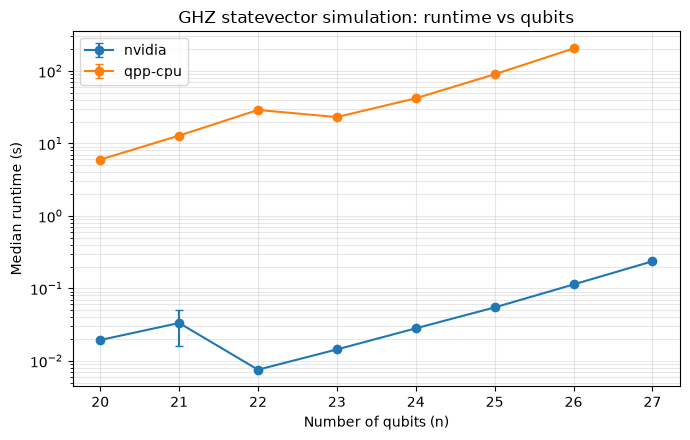

In [51]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4.5))
for target, g in df.groupby("target"):
    ax.errorbar(g["n"], g["median_s"], yerr=g["std_s"], marker="o",
                capsize=3, label=target)
ax.set_yscale("log")
ax.set_xlabel("Number of qubits (n)")
ax.set_ylabel("Median runtime (s)")
ax.set_title("GHZ statevector simulation: runtime vs qubits")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("results/ghz_benchmark.png", dpi=200)

In [52]:
for target in ("qpp-cpu", "nvidia"):
    cudaq.set_target(target)
    for shots in (1, 10, 100):
        t, _ = time_runs(lambda: run_once(18, shots), warmup=2, repeats=3)
        print(target, shots, f"{t:.4f}s")

qpp-cpu 1 0.4578s
qpp-cpu 10 0.3972s
qpp-cpu 100 0.4394s
nvidia 1 0.0067s
nvidia 10 0.0069s
nvidia 100 0.0071s
